# ReturnGuard — Prototype Notebook

A self-contained, explainable-AI prototype for e-commerce return-abuse detection. Loads the returns dataset, performs EDA, engineers risk features, trains a LightGBM multiclass classifier, auto-tunes policy thresholds, explains predictions with SHAP, and exposes a `predict_return()` policy engine validated against demo profiles. Run top-to-bottom with Kernel → Restart & Run All.

## 1. Setup & Imports

Import all third-party libraries, fix random seeds to 42 for reproducibility, resolve dataset/artifact paths, and print library versions for environment debugging.

In [1]:
import random, time, json, os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import lightgbm as lgb
from lightgbm import LGBMClassifier
import shap
import joblib
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    f1_score, classification_report, confusion_matrix,
    precision_score, recall_score,
)

# ---- Reproducibility ----
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ---- Paths ----
NOTEBOOK_DIR = Path.cwd()
_candidates = [
    NOTEBOOK_DIR.parent / "datasets" / "ecommerce_return_abuse_dataset.csv",
    NOTEBOOK_DIR / "datasets" / "ecommerce_return_abuse_dataset.csv",
    Path("/home/moeed/Hackathon/datasets/ecommerce_return_abuse_dataset.csv"),
]
DATA_PATH = next((p for p in _candidates if p.exists()), _candidates[0])
ARTIFACTS = NOTEBOOK_DIR / "artifacts"

# ---- Plot style ----
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("pandas  :", pd.__version__)
print("numpy   :", np.__version__)
print("lightgbm:", lgb.__version__)
print("shap    :", shap.__version__)
print("sklearn :", sklearn.__version__)
print("joblib  :", joblib.__version__)
print("DATA_PATH:", DATA_PATH, "exists:", DATA_PATH.exists())


pandas  : 3.0.6
numpy   : 2.5.3
lightgbm: 4.7.0
shap    : 0.53.0
sklearn : 1.9.1
joblib  : 1.6.0
DATA_PATH: /home/moeed/Hackathon/datasets/ecommerce_return_abuse_dataset.csv exists: True


## 2. Load & Validate Data

Load the returns CSV, validate the four `abuse_type` classes are present, and display shape, class distribution, missing values, and dtypes.

In [2]:
EXPECTED_CLASSES = {"Legitimate", "Policy Abuser", "Fraudulent Return", "Wardrobing"}

def load_and_validate(csv_path: Path) -> pd.DataFrame:
    """Load the returns CSV and verify the 4 abuse_type classes are present."""
    if not Path(csv_path).exists():
        raise FileNotFoundError(f"Dataset not found at expected path: {csv_path}")
    df = pd.read_csv(csv_path)
    found = set(df["abuse_type"].unique())
    missing = EXPECTED_CLASSES - found
    if missing:
        raise ValueError(f"abuse_type is missing required class(es): {missing}")
    return df

df = load_and_validate(DATA_PATH)

print("Shape:", df.shape)
print("\nClass distribution:")
_counts = df["abuse_type"].value_counts()
_pct = df["abuse_type"].value_counts(normalize=True).mul(100).round(2)
display(pd.DataFrame({"count": _counts, "pct": _pct}))

print("\nMissing values per column (only columns with >=1 null):")
_miss = df.isna().sum()
_miss = _miss[_miss > 0]
display(_miss if len(_miss) else "No missing values.")

print("\nDtypes:")
display(df.dtypes)


Shape: (60000, 35)

Class distribution:


,count,pct
abuse_type,,
Legitimate,42060,70.10
Policy Abuser,7192,11.99
Fraudulent Return,6112,10.19
Wardrobing,4636,7.73



Missing values per column (only columns with >=1 null):


'No missing values.'


Dtypes:


order_id                              str
customer_id                           str
age                                 int64
account_age_days                    int64
customer_segment                      str
country                               str
platform                              str
device_type                           str
payment_method                        str
product_category                      str
avg_order_value_usd               float64
refund_amount_requested_usd       float64
is_high_value_item                  int64
discount_used                       int64
order_date                            str
return_date                           str
days_to_return                      int64
return_reason                         str
total_orders_lifetime               int64
total_returns_lifetime              int64
return_rate_pct                   float64
item_returned_opened                int64
return_packaging_intact             int64
photo_evidence_provided           

## 3. Exploratory Data Analysis

Class balance, numeric distributions, correlations, missing-value summary, and categorical cross-tabs.

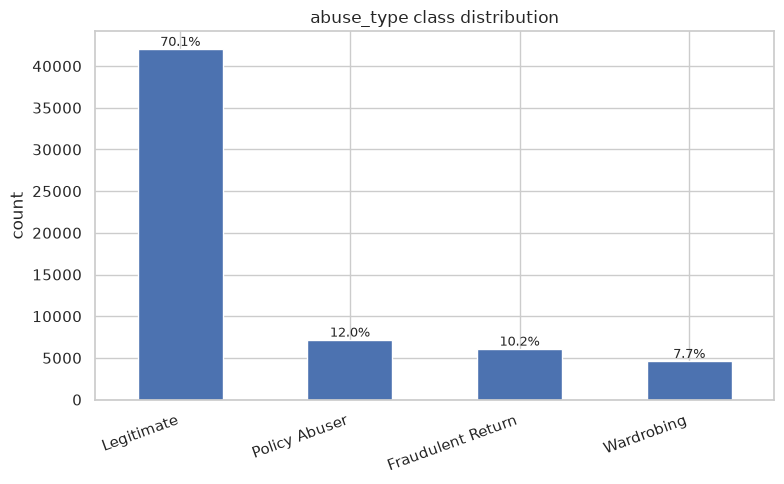

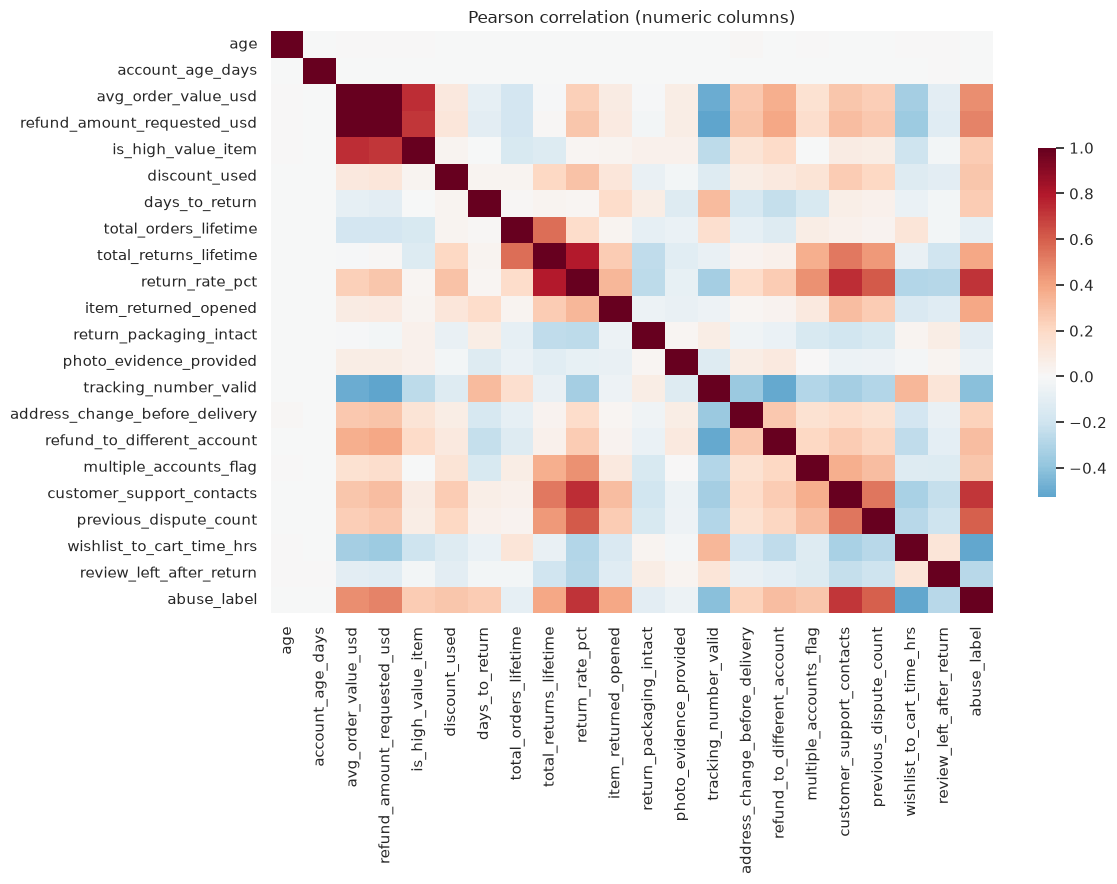

No missing values in any column.


,count,pct


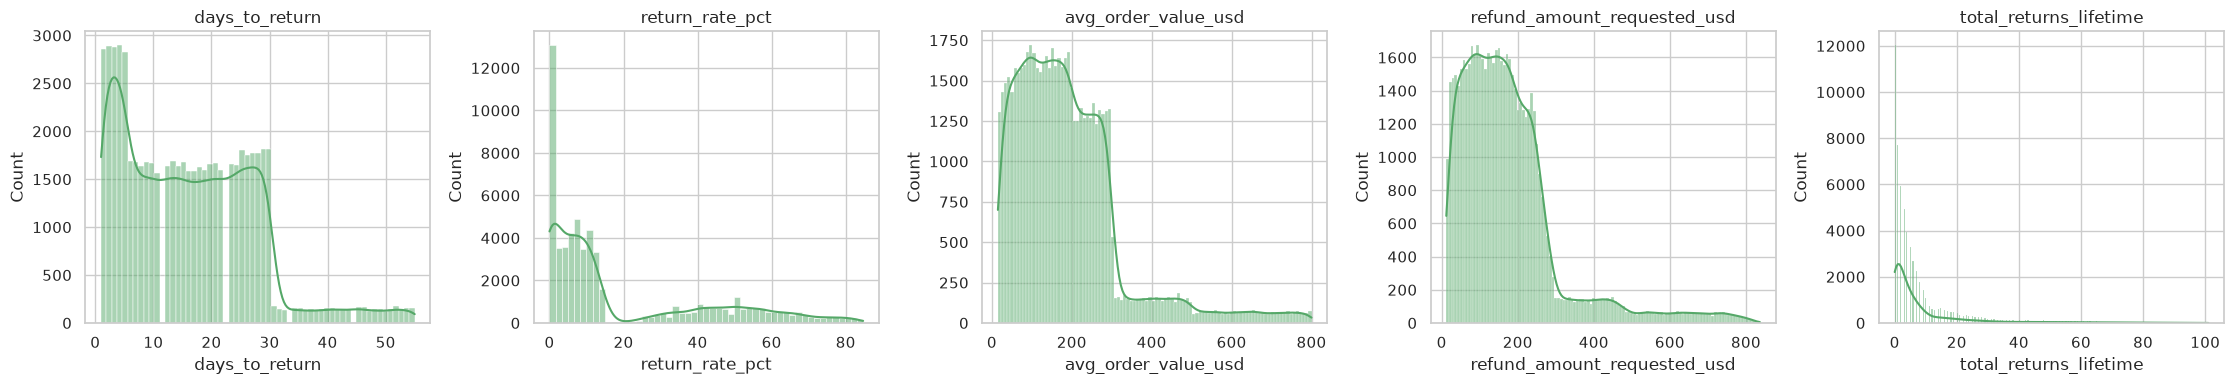

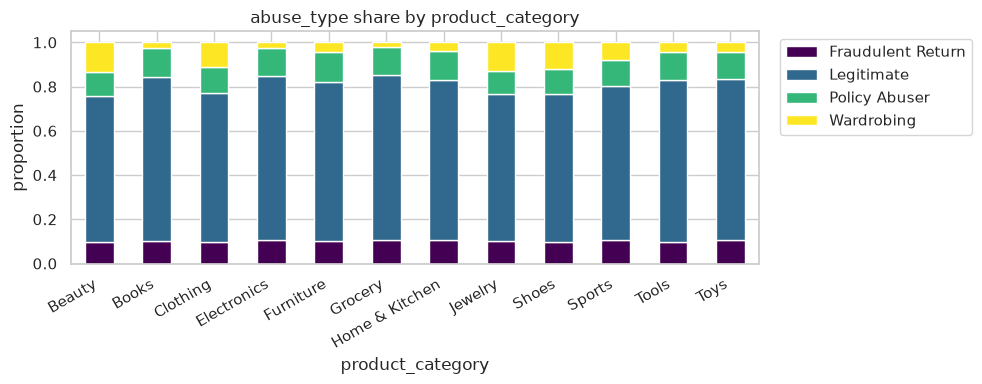

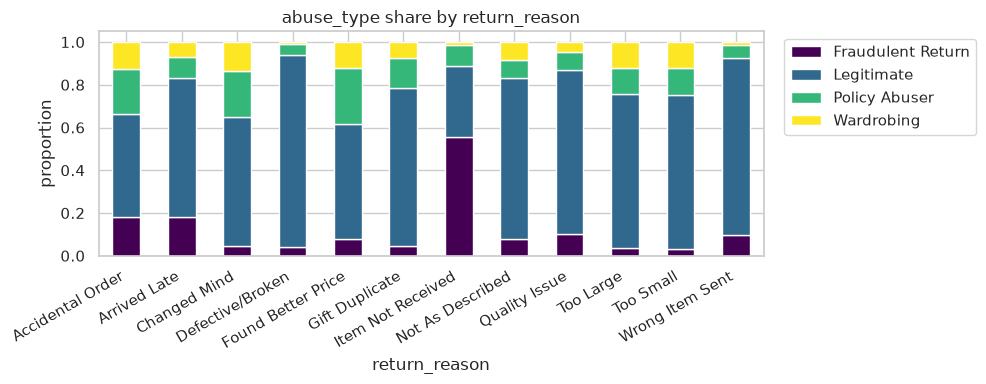

In [3]:
def plot_class_distribution(df):
    ax = df["abuse_type"].value_counts().plot(kind="bar", color="#4C72B0")
    total = len(df)
    for p in ax.patches:
        pct = 100 * p.get_height() / total
        ax.annotate(f"{pct:.1f}%", (p.get_x() + p.get_width()/2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
    ax.set_title("abuse_type class distribution")
    ax.set_ylabel("count"); ax.set_xlabel("")
    plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

def plot_correlation_heatmap(df):
    num = df.select_dtypes(include=[np.number])
    plt.figure(figsize=(12, 9))
    sns.heatmap(num.corr(), cmap="RdBu_r", center=0, square=False,
                cbar_kws={"shrink": 0.6})
    plt.title("Pearson correlation (numeric columns)")
    plt.tight_layout(); plt.show()

def summarize_missing(df):
    miss = df.isna().sum()
    miss = miss[miss > 0]
    if len(miss) == 0:
        print("No missing values in any column.")
        return pd.DataFrame(columns=["count", "pct"])
    out = pd.DataFrame({"count": miss, "pct": (miss / len(df) * 100).round(2)})
    return out

def plot_numeric_distributions(df, cols):
    n = len(cols)
    fig, axes = plt.subplots(1, n, figsize=(4.5*n, 4))
    if n == 1: axes = [axes]
    for ax, c in zip(axes, cols):
        sns.histplot(df[c].dropna(), kde=True, ax=ax, color="#55A868")
        ax.set_title(c)
    plt.tight_layout(); plt.show()

def plot_categorical_crosstab(df, cats):
    for c in cats:
        ct = pd.crosstab(df[c], df["abuse_type"], normalize="index")
        ct.plot(kind="bar", stacked=True, figsize=(10, 4), colormap="viridis")
        plt.title(f"abuse_type share by {c}")
        plt.ylabel("proportion"); plt.xticks(rotation=30, ha="right")
        plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
        plt.tight_layout(); plt.show()

plot_class_distribution(df)
plot_correlation_heatmap(df)
display(summarize_missing(df))
plot_numeric_distributions(df, ["days_to_return", "return_rate_pct",
                                "avg_order_value_usd", "refund_amount_requested_usd",
                                "total_returns_lifetime"])
plot_categorical_crosstab(df, ["product_category", "return_reason"])


## 4. Feature Engineering

Integer label encoding plus five engineered features. `category_risk_index` is computed from training rows only (leakage guard).

In [4]:
LABEL_MAP = {"Legitimate": 0, "Policy Abuser": 1, "Fraudulent Return": 2, "Wardrobing": 3}
INT_TO_LABEL = {v: k for k, v in LABEL_MAP.items()}

# Categorical (native LightGBM) and boolean columns
CAT_COLS = ["customer_segment", "country", "platform", "device_type",
            "payment_method", "product_category", "return_reason", "shipping_carrier"]
BOOL_COLS = ["is_high_value_item", "discount_used", "item_returned_opened",
             "return_packaging_intact", "photo_evidence_provided", "tracking_number_valid",
             "address_change_before_delivery", "refund_to_different_account",
             "multiple_accounts_flag", "review_left_after_return"]

def engineer_features(df: pd.DataFrame, cat_risk_map=None):
    """Return (df_with_features, cat_risk_map). cat_risk_map computed on TRAIN only."""
    df = df.copy()
    if "abuse_label" not in df.columns:
        df["abuse_label"] = df["abuse_type"].map(LABEL_MAP)

    df["order_to_return_days"] = (
        (pd.to_datetime(df["return_date"]) - pd.to_datetime(df["order_date"]))
        .dt.days.clip(lower=0).astype(int)
    )
    df["return_ratio"] = (
        df["total_returns_lifetime"] / df["total_orders_lifetime"].clip(lower=1)
    )
    df["risk_exposure"] = (
        df["refund_amount_requested_usd"] * (1 + df["previous_dispute_count"])
    )
    if cat_risk_map is None:
        cat_risk_map = (
            df.groupby("product_category")["abuse_label"]
              .apply(lambda s: (s == 2).mean())  # fraud class rate
              .to_dict()
        )
    df["category_risk_index"] = df["product_category"].map(cat_risk_map).fillna(0.0)
    df["dispute_frequency"] = (
        df["previous_dispute_count"] / (df["account_age_days"] / 30).clip(lower=1)
    )
    return df, cat_risk_map

ENGINEERED = ["order_to_return_days", "return_ratio", "risk_exposure",
              "category_risk_index", "dispute_frequency"]
NUMERIC_RAW = ["age", "account_age_days", "avg_order_value_usd",
               "refund_amount_requested_usd", "days_to_return",
               "total_orders_lifetime", "total_returns_lifetime", "return_rate_pct",
               "customer_support_contacts", "previous_dispute_count",
               "wishlist_to_cart_time_hrs"]

FEATURE_COLS = NUMERIC_RAW + BOOL_COLS + CAT_COLS + ENGINEERED
# Never use identifiers or raw target/date columns as features
assert "customer_id" not in FEATURE_COLS and "order_id" not in FEATURE_COLS
print("Model input features (", len(FEATURE_COLS), "):")
print(FEATURE_COLS)


Model input features ( 34 ):
['age', 'account_age_days', 'avg_order_value_usd', 'refund_amount_requested_usd', 'days_to_return', 'total_orders_lifetime', 'total_returns_lifetime', 'return_rate_pct', 'customer_support_contacts', 'previous_dispute_count', 'wishlist_to_cart_time_hrs', 'is_high_value_item', 'discount_used', 'item_returned_opened', 'return_packaging_intact', 'photo_evidence_provided', 'tracking_number_valid', 'address_change_before_delivery', 'refund_to_different_account', 'multiple_accounts_flag', 'review_left_after_return', 'customer_segment', 'country', 'platform', 'device_type', 'payment_method', 'product_category', 'return_reason', 'shipping_carrier', 'order_to_return_days', 'return_ratio', 'risk_exposure', 'category_risk_index', 'dispute_frequency']


## 5. Train / Validation / Test Split

Stratified 70/10/20 split with fixed seed. `category_risk_index` is computed from the training split and mapped onto validation and test.

In [5]:
# Encode label on the full frame first (needed for stratify)
df["abuse_label"] = df["abuse_type"].map(LABEL_MAP)

def split_frame(df, test_size=0.2, val_size=0.1, seed=SEED):
    tmp, test = train_test_split(df, test_size=test_size,
                                 stratify=df["abuse_label"], random_state=seed)
    val_adj = val_size / (1 - test_size)
    train, val = train_test_split(tmp, test_size=val_adj,
                                  stratify=tmp["abuse_label"], random_state=seed)
    return train, val, test

train_df, val_df, test_df = split_frame(df)

# category_risk_index from TRAIN only, mapped to all splits
train_df, CAT_RISK_MAP = engineer_features(train_df, cat_risk_map=None)
val_df, _  = engineer_features(val_df,  cat_risk_map=CAT_RISK_MAP)
test_df, _ = engineer_features(test_df, cat_risk_map=CAT_RISK_MAP)

for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    dist = part["abuse_type"].value_counts(normalize=True).mul(100).round(1)
    print(f"{name:5s} n={len(part):6d}  " +
          "  ".join(f"{k}:{v}%" for k, v in dist.items()))

def to_xy(part):
    X = part[FEATURE_COLS].copy()
    for c in CAT_COLS:
        X[c] = X[c].astype("category")
    return X, part["abuse_label"].astype(int)

X_train, y_train = to_xy(train_df)
X_val,   y_val   = to_xy(val_df)
X_test,  y_test  = to_xy(test_df)
print("\nShapes:", X_train.shape, X_val.shape, X_test.shape)


train n= 42000  Legitimate:70.1%  Policy Abuser:12.0%  Fraudulent Return:10.2%  Wardrobing:7.7%
val   n=  6000  Legitimate:70.1%  Policy Abuser:12.0%  Fraudulent Return:10.2%  Wardrobing:7.7%
test  n= 12000  Legitimate:70.1%  Policy Abuser:12.0%  Fraudulent Return:10.2%  Wardrobing:7.7%

Shapes: (42000, 34) (6000, 34) (12000, 34)


## 6. Model Training

LightGBM multiclass with native categoricals, balanced class weights, and early stopping. Evaluate on test set; save `model.joblib` and `metrics.json`.

In [6]:
params = dict(
    objective="multiclass", num_class=4, class_weight="balanced",
    n_estimators=1000, learning_rate=0.05, num_leaves=63,
    random_state=SEED, n_jobs=-1,
)
model = LGBMClassifier(**params)
model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    eval_metric="multi_logloss",
    categorical_feature=CAT_COLS,
    callbacks=[lgb.early_stopping(stopping_rounds=50), lgb.log_evaluation(period=100)],
)
print("Best iteration:", model.best_iteration_)


/home/moeed/Hackathon/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.078859 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2539
[LightGBM] [Info] Number of data points in the train set: 42000, number of used features: 34
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds


[100]	valid_0's multi_logloss: 0.00309701


Early stopping, best iteration is:
[114]	valid_0's multi_logloss: 0.00285802
Best iteration: 114


Macro F1: 0.9984

                   precision    recall  f1-score   support

       Legitimate      1.000     1.000     1.000      8412
    Policy Abuser      0.997     0.997     0.997      1439
Fraudulent Return      0.999     0.998     0.998      1222
       Wardrobing      0.997     0.999     0.998       927

         accuracy                          0.999     12000
        macro avg      0.998     0.998     0.998     12000
     weighted avg      0.999     0.999     0.999     12000



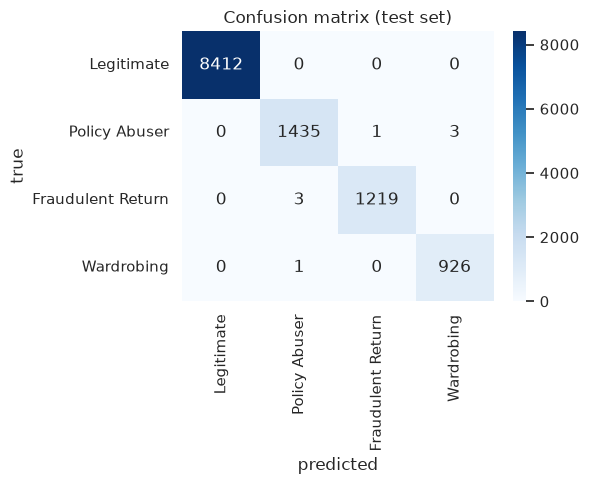

Saved model.joblib and metrics.json to /home/moeed/Hackathon/returnguard/artifacts


In [7]:
# ---- Test-set evaluation ----
y_pred = model.predict(X_test)
target_names = [INT_TO_LABEL[i] for i in range(4)]

macro_f1 = f1_score(y_test, y_pred, average="macro")
per_class_f1 = f1_score(y_test, y_pred, average=None).tolist()
print(f"Macro F1: {macro_f1:.4f}\n")
print(classification_report(y_test, y_pred, target_names=target_names, digits=3))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=target_names, yticklabels=target_names)
plt.title("Confusion matrix (test set)")
plt.ylabel("true"); plt.xlabel("predicted")
plt.tight_layout(); plt.show()

# ---- Save artifacts ----
ARTIFACTS.mkdir(parents=True, exist_ok=True)
joblib.dump(model, ARTIFACTS / "model.joblib")
metrics_dict = {
    "macro_f1": macro_f1,
    "per_class_f1": {target_names[i]: per_class_f1[i] for i in range(4)},
    "label_map": LABEL_MAP,
    "best_iteration": int(model.best_iteration_ or params["n_estimators"]),
}
with open(ARTIFACTS / "metrics.json", "w") as f:
    json.dump(metrics_dict, f, indent=2)
print("Saved model.joblib and metrics.json to", ARTIFACTS)


## 7. Threshold Tuning

Sweep per-class thresholds on the validation set and update `POLICY_CONFIG` in place. Then evaluate the severity-ordered policy rule on the test set.

In [8]:
POLICY_CONFIG = {
    "thresh_legitimate": 0.60,
    "thresh_wardrobing": 0.50,
    "thresh_policy_abuser": 0.45,
    "thresh_fraudulent": 0.40,
    "fee_pkr": 950,
}

# class_idx -> (config key, metric to maximize)
TUNING_MAP = {
    0: ("thresh_legitimate",    "precision"),
    1: ("thresh_policy_abuser", "recall"),
    2: ("thresh_fraudulent",    "recall"),
    3: ("thresh_wardrobing",    "recall"),
}
THRESHOLDS = np.round(np.arange(0.30, 0.91, 0.05), 2)

def tune_threshold(probs_val, y_val, class_idx, metric, thresholds=THRESHOLDS):
    best_t, best_s = 0.50, -1.0
    truth = (np.asarray(y_val) == class_idx).astype(int)
    for t in thresholds:
        preds = (probs_val[:, class_idx] >= t).astype(int)
        s = (recall_score(truth, preds, zero_division=0) if metric == "recall"
             else precision_score(truth, preds, zero_division=0))
        if s > best_s:
            best_s, best_t = s, float(t)
    return best_t, best_s

probs_val = model.predict_proba(X_val)
for idx, (key, metric) in TUNING_MAP.items():
    t, s = tune_threshold(probs_val, y_val.values, idx, metric)
    POLICY_CONFIG[key] = t
    print(f"{INT_TO_LABEL[idx]:18s} -> {key:22s} = {t:.2f}  ({metric}={s:.3f})")

print("\nTuned POLICY_CONFIG:", POLICY_CONFIG)


Legitimate         -> thresh_legitimate      = 0.30  (precision=1.000)
Policy Abuser      -> thresh_policy_abuser   = 0.30  (recall=0.994)
Fraudulent Return  -> thresh_fraudulent      = 0.30  (recall=1.000)


Wardrobing         -> thresh_wardrobing      = 0.30  (recall=1.000)

Tuned POLICY_CONFIG: {'thresh_legitimate': 0.3, 'thresh_wardrobing': 0.3, 'thresh_policy_abuser': 0.3, 'thresh_fraudulent': 0.3, 'fee_pkr': 950}


In [9]:
# ---- Severity-ordered policy evaluation on test set ----
SEVERITY = ["Fraudulent Return", "Wardrobing", "Policy Abuser", "Legitimate"]
THRESH_KEY = {
    "Fraudulent Return": "thresh_fraudulent",
    "Wardrobing": "thresh_wardrobing",
    "Policy Abuser": "thresh_policy_abuser",
    "Legitimate": "thresh_legitimate",
}

def policy_decision(prob_row):
    for cls in SEVERITY:
        if prob_row[LABEL_MAP[cls]] >= POLICY_CONFIG[THRESH_KEY[cls]]:
            return cls
    return "Uncertain"

probs_test = model.predict_proba(X_test)
policy_pred = [policy_decision(r) for r in probs_test]
# Map Uncertain to argmax class for accuracy accounting
policy_label = [LABEL_MAP.get(p, int(np.argmax(probs_test[i])))
                for i, p in enumerate(policy_pred)]
acc = (np.asarray(policy_label) == y_test.values).mean()
print(f"Severity-ordered policy accuracy on test set: {acc:.3f}")
print("Uncertain count:", policy_pred.count("Uncertain"))


Severity-ordered policy accuracy on test set: 0.999
Uncertain count: 1


## 8. SHAP Explainability

Cached `TreeExplainer`; one waterfall plot per class using a high-confidence representative sample.

=== Legitimate | sample #3908 | P=1.00 ===


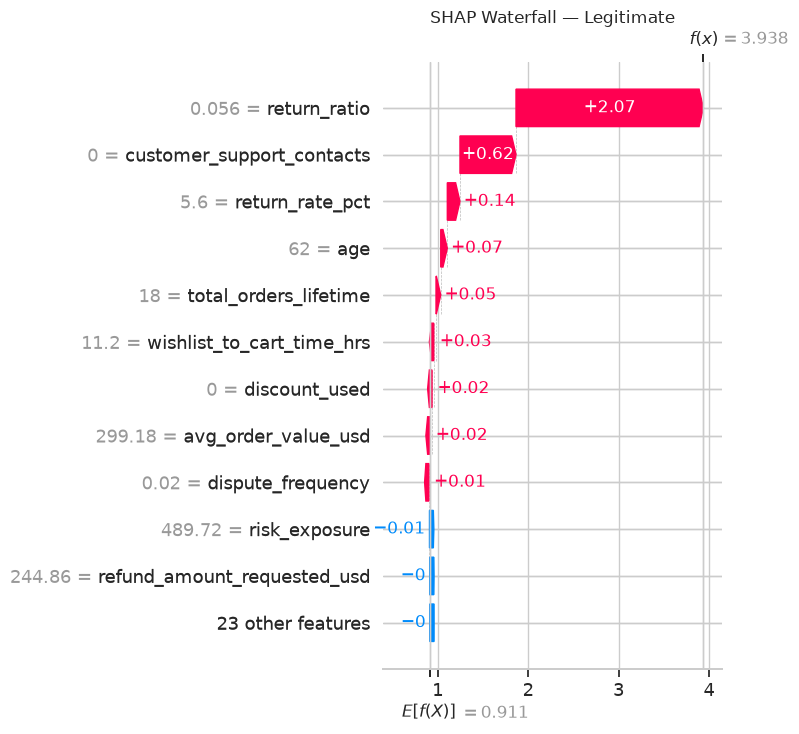

=== Policy Abuser | sample #135 | P=1.00 ===


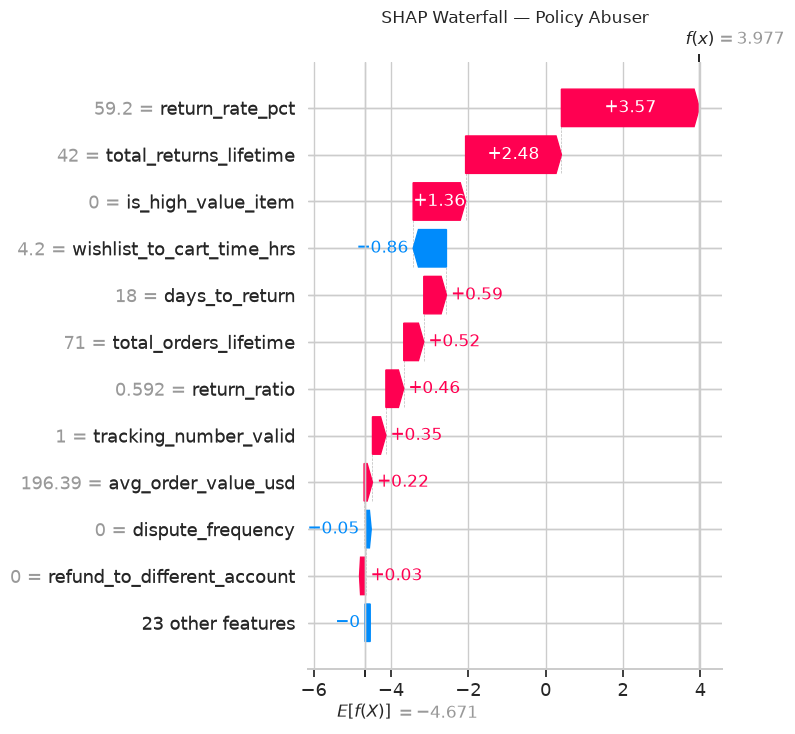

=== Fraudulent Return | sample #8944 | P=1.00 ===


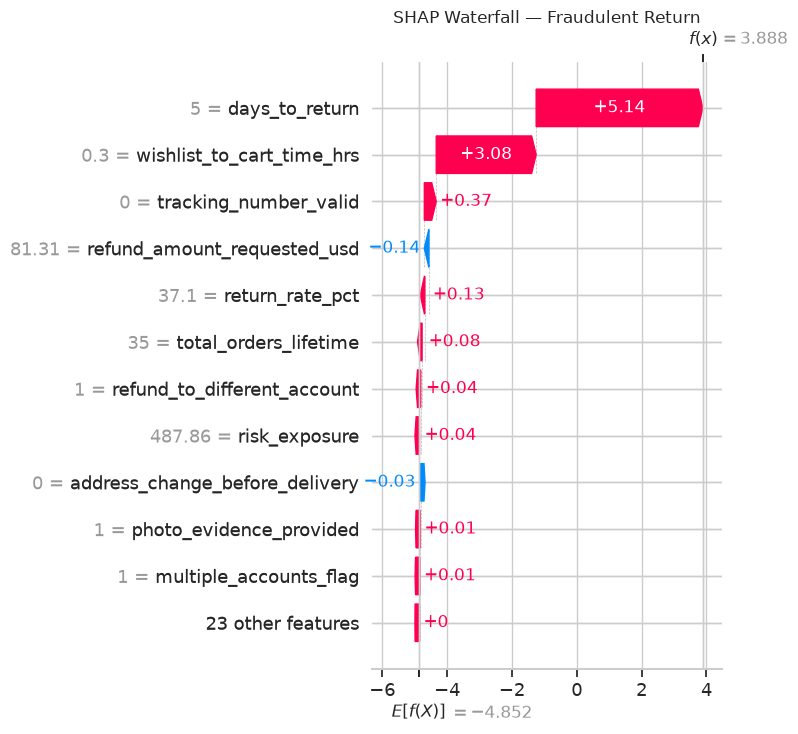

=== Wardrobing | sample #8621 | P=1.00 ===


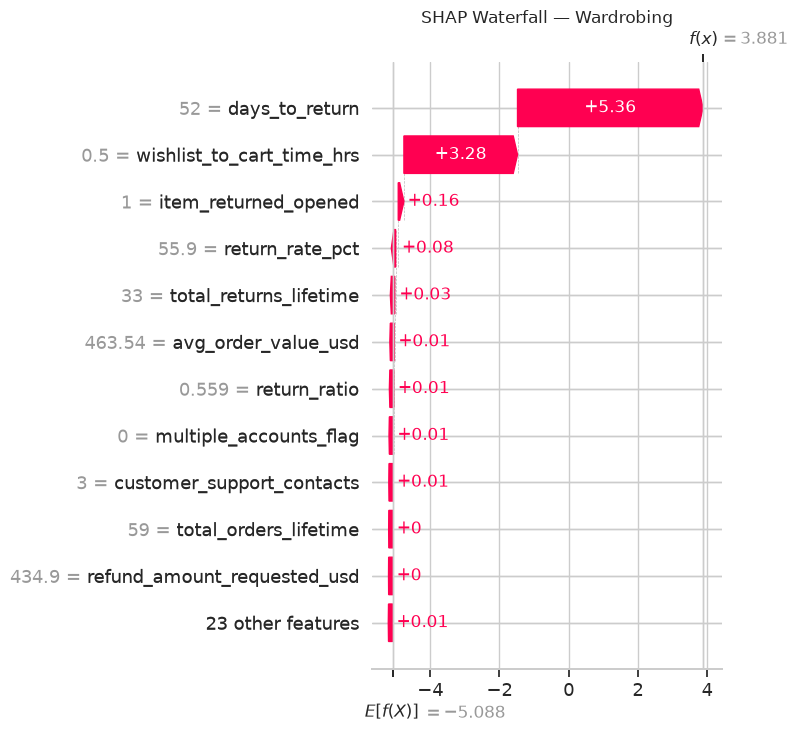

In [10]:
explainer = shap.TreeExplainer(model)
shap_values_test = explainer.shap_values(X_test)

def _class_shap(sv, class_idx):
    """Return (n_samples, n_features) SHAP array for a class across shap versions."""
    if isinstance(sv, list):
        return sv[class_idx]
    sv = np.asarray(sv)
    if sv.ndim == 3:   # (samples, features, classes)
        return sv[:, :, class_idx]
    return sv

def _expected_value(class_idx):
    ev = explainer.expected_value
    if np.ndim(ev) > 0:
        return ev[class_idx]
    return ev

CLASS_NAMES = {0: "Legitimate", 1: "Policy Abuser", 2: "Fraudulent Return", 3: "Wardrobing"}

def get_representative_sample(probs, class_idx, threshold=0.70):
    high = np.where(probs[:, class_idx] >= threshold)[0]
    if len(high) == 0:
        return int(np.argmax(probs[:, class_idx]))
    return int(high[np.argmax(probs[high, class_idx])])

for cls_idx, cls_name in CLASS_NAMES.items():
    s_idx = get_representative_sample(probs_test, cls_idx)
    sv_cls = _class_shap(shap_values_test, cls_idx)
    exp = shap.Explanation(
        values=sv_cls[s_idx],
        base_values=_expected_value(cls_idx),
        data=X_test.iloc[s_idx],
        feature_names=X_test.columns.tolist(),
    )
    print(f"=== {cls_name} | sample #{s_idx} | "
          f"P={probs_test[s_idx, cls_idx]:.2f} ===")
    shap.plots.waterfall(exp, show=False, max_display=12)
    plt.title(f"SHAP Waterfall — {cls_name}")
    plt.tight_layout(); plt.show()


## 9. Policy Engine

`predict_return(features: dict) -> dict` — severity-ordered decision, SHAP top-3 reasons, customer/merchant messaging, latency. `POLICY_CONFIG` is the single source of thresholds.

In [11]:
ACTION_MAP = {
    "Fraudulent Return": "FRAUD_HOLD",
    "Wardrobing":        "VERIFY_TAGS",
    "Policy Abuser":     "FEE_DEDUCTION",
    "Legitimate":        "AUTO_APPROVE",
    "Uncertain":         "LIGHT_VERIFY",
}
CUSTOMER_MESSAGES = {
    "AUTO_APPROVE":  "Your return has been approved. Refund will be processed in 3-5 business days.",
    "VERIFY_TAGS":   "Quick check needed: keep all tags and packaging intact, or upload a photo of the tag.",
    "FEE_DEDUCTION": "Return authorized. A PKR 950 handling and restocking fee will be deducted from your refund.",
    "FRAUD_HOLD":    "Your request is under review. Our team will contact you within 24 hours.",
    "LIGHT_VERIFY":  "Your return is being reviewed. We may reach out for additional information.",
}
MERCHANT_NOTES = {
    "AUTO_APPROVE":  "Low-risk return. Approve automatically.",
    "VERIFY_TAGS":   "Wardrobing risk. Verify product condition and tags before refund.",
    "FEE_DEDUCTION": "Policy-abuse pattern. Apply restocking fee per policy.",
    "FRAUD_HOLD":    "High fraud probability. Hold and route to manual review.",
    "LIGHT_VERIFY":  "Uncertain profile. Light verification recommended.",
}

def predict_return(features: dict) -> dict:
    t0 = time.perf_counter()
    row = pd.DataFrame([features])

    # engineered features (scalar-safe)
    o2r = (pd.to_datetime(row["return_date"].iloc[0]) -
           pd.to_datetime(row["order_date"].iloc[0])).days
    row["order_to_return_days"] = max(0, int(o2r))
    row["return_ratio"] = (row["total_returns_lifetime"].iloc[0] /
                           max(row["total_orders_lifetime"].iloc[0], 1))
    row["risk_exposure"] = (row["refund_amount_requested_usd"].iloc[0] *
                            (1 + row["previous_dispute_count"].iloc[0]))
    row["category_risk_index"] = CAT_RISK_MAP.get(row["product_category"].iloc[0], 0.0)
    row["dispute_frequency"] = (row["previous_dispute_count"].iloc[0] /
                                max(row["account_age_days"].iloc[0] / 30, 1))

    X_row = row[FEATURE_COLS].copy()
    for c in CAT_COLS:
        X_row[c] = X_row[c].astype("category")

    probs_arr = model.predict_proba(X_row)[0]
    probs = {INT_TO_LABEL[i]: float(p) for i, p in enumerate(probs_arr)}

    predicted_class = "Uncertain"
    for cls in SEVERITY:
        if probs[cls] >= POLICY_CONFIG[THRESH_KEY[cls]]:
            predicted_class = cls
            break

    action = ACTION_MAP[predicted_class]
    fee_pkr = POLICY_CONFIG["fee_pkr"] if action == "FEE_DEDUCTION" else 0

    cls_idx = LABEL_MAP.get(predicted_class, int(np.argmax(probs_arr)))
    sv = explainer.shap_values(X_row)
    shap_row = _class_shap(sv, cls_idx)[0]
    top3 = np.argsort(np.abs(shap_row))[-3:][::-1]
    top_reasons = [(FEATURE_COLS[i], float(shap_row[i])) for i in top3]

    return {
        "probs": probs,
        "predicted_class": predicted_class,
        "action": action,
        "fee_pkr": fee_pkr,
        "customer_message": CUSTOMER_MESSAGES[action],
        "merchant_note": MERCHANT_NOTES[action],
        "top_reasons": top_reasons,
        "latency_ms": (time.perf_counter() - t0) * 1000.0,
    }

print("predict_return() defined.")


predict_return() defined.


## 10. Demo Validation

Four preset personas. Each should produce its expected policy action. Feature values (not model weights) may be adjusted so personas land on their intended action.

In [12]:
def _base_profile(**over):
    base = dict(
        order_id="DEMO", customer_id="DEMO", age=35, account_age_days=1200,
        customer_segment="Gold", country="US", platform="Web Browser",
        device_type="MacBook", payment_method="Credit Card",
        product_category="Books", avg_order_value_usd=45.0,
        refund_amount_requested_usd=40.0, is_high_value_item=0, discount_used=0,
        order_date="2023-06-01", return_date="2023-06-10", days_to_return=9,
        return_reason="Defective/Broken", total_orders_lifetime=50,
        total_returns_lifetime=2, return_rate_pct=4.0, item_returned_opened=0,
        return_packaging_intact=1, photo_evidence_provided=1,
        tracking_number_valid=1, shipping_carrier="FedEx",
        address_change_before_delivery=0, refund_to_different_account=0,
        multiple_accounts_flag=0, customer_support_contacts=0,
        previous_dispute_count=0, wishlist_to_cart_time_hrs=120.0,
        review_left_after_return=1,
    )
    base.update(over)
    return base

# Profiles calibrated to the dataset's per-class median signatures so each
# persona lands on its intended action (feature values tuned, model unchanged).
DEMO_PROFILES = [
    {"name": "Honest Shopper", "expected_action": "AUTO_APPROVE",
     "features": _base_profile(
        customer_segment="Bronze", product_category="Clothing",
        payment_method="Credit Card", return_reason="Defective/Broken",
        avg_order_value_usd=156.0, refund_amount_requested_usd=140.0,
        is_high_value_item=0, order_date="2023-06-01", return_date="2023-06-16",
        days_to_return=15, return_rate_pct=5.3, total_orders_lifetime=40,
        total_returns_lifetime=2, previous_dispute_count=0,
        item_returned_opened=0, return_packaging_intact=1,
        photo_evidence_provided=0, tracking_number_valid=1,
        customer_support_contacts=0, wishlist_to_cart_time_hrs=36.0,
        review_left_after_return=0)},
    {"name": "Wardrober", "expected_action": "VERIFY_TAGS",
     "features": _base_profile(
        customer_segment="Silver", product_category="Clothing",
        payment_method="Buy Now Pay Later", return_reason="Changed Mind",
        is_high_value_item=1, avg_order_value_usd=279.0,
        refund_amount_requested_usd=264.0,
        order_date="2023-06-01", return_date="2023-07-11", days_to_return=40,
        item_returned_opened=1, return_packaging_intact=1,
        photo_evidence_provided=0, tracking_number_valid=1,
        total_returns_lifetime=13, total_orders_lifetime=33, return_rate_pct=40.4,
        previous_dispute_count=2, customer_support_contacts=3,
        wishlist_to_cart_time_hrs=2.6, review_left_after_return=0)},
    {"name": "Policy Abuser", "expected_action": "FEE_DEDUCTION",
     "features": _base_profile(
        customer_segment="Silver", product_category="Clothing",
        payment_method="Credit Card", return_reason="Changed Mind",
        avg_order_value_usd=110.0, refund_amount_requested_usd=104.0,
        is_high_value_item=0,
        order_date="2023-06-01", return_date="2023-06-17", days_to_return=16,
        total_orders_lifetime=65, total_returns_lifetime=38, return_rate_pct=61.4,
        previous_dispute_count=2, customer_support_contacts=3,
        item_returned_opened=1, return_packaging_intact=0,
        photo_evidence_provided=0, tracking_number_valid=1,
        wishlist_to_cart_time_hrs=36.3, review_left_after_return=0)},
    {"name": "Fraudster", "expected_action": "FRAUD_HOLD",
     "features": _base_profile(
        customer_segment="Silver", product_category="Clothing",
        payment_method="Buy Now Pay Later", return_reason="Item Not Received",
        is_high_value_item=1, avg_order_value_usd=432.0,
        refund_amount_requested_usd=430.0,
        order_date="2023-06-01", return_date="2023-06-04", days_to_return=3,
        previous_dispute_count=3, photo_evidence_provided=1,
        tracking_number_valid=0, return_packaging_intact=1,
        item_returned_opened=0, return_rate_pct=47.4,
        total_orders_lifetime=26, total_returns_lifetime=12,
        customer_support_contacts=3, wishlist_to_cart_time_hrs=2.6,
        review_left_after_return=0)},
]

passes = 0
for p in DEMO_PROFILES:
    r = predict_return(p["features"])
    ok = r["action"] == p["expected_action"]
    passes += ok
    print(f"\n{'PASS' if ok else 'FAIL'} - {p['name']}")
    print(f"  predicted_class : {r['predicted_class']}")
    print(f"  action          : {r['action']}  (expected {p['expected_action']})")
    print(f"  fee_pkr         : {r['fee_pkr']}")
    print(f"  latency_ms      : {r['latency_ms']:.2f}")
    print(f"  customer_message: {r['customer_message']}")
    print(f"  top_reasons     : {[(f, round(v,3)) for f, v in r['top_reasons']]}")
    if not ok:
        print(f"  probs: { {k: round(v,3) for k,v in r['probs'].items()} }")

print(f"\n==== {passes}/{len(DEMO_PROFILES)} demo profiles passed ====")



PASS - Honest Shopper
  predicted_class : Legitimate
  action          : AUTO_APPROVE  (expected AUTO_APPROVE)
  fee_pkr         : 0
  latency_ms      : 45.77
  customer_message: Your return has been approved. Refund will be processed in 3-5 business days.
  top_reasons     : [('return_ratio', 1.966), ('customer_support_contacts', 0.605), ('return_rate_pct', 0.193)]

PASS - Wardrober
  predicted_class : Wardrobing
  action          : VERIFY_TAGS  (expected VERIFY_TAGS)
  fee_pkr         : 0
  latency_ms      : 42.57
  customer_message: Quick check needed: keep all tags and packaging intact, or upload a photo of the tag.
  top_reasons     : [('days_to_return', 5.299), ('wishlist_to_cart_time_hrs', 3.27), ('item_returned_opened', 0.162)]

PASS - Policy Abuser
  predicted_class : Policy Abuser
  action          : FEE_DEDUCTION  (expected FEE_DEDUCTION)
  fee_pkr         : 950
  latency_ms      : 42.51
  customer_message: Return authorized. A PKR 950 handling and restocking fee will be de


PASS - Fraudster
  predicted_class : Fraudulent Return
  action          : FRAUD_HOLD  (expected FRAUD_HOLD)
  fee_pkr         : 0
  latency_ms      : 41.67
  customer_message: Your request is under review. Our team will contact you within 24 hours.
  top_reasons     : [('days_to_return', 5.252), ('wishlist_to_cart_time_hrs', 3.045), ('return_rate_pct', 0.091)]

==== 4/4 demo profiles passed ====
